# 04 · Interpretabilidad y robustez: Grad-CAM + prueba con imágenes de campo

Un F1 macro de ~0,98 en el test de PlantVillage no dice si el modelo sirve fuera del laboratorio. Este notebook intenta responder dos preguntas:

1. **¿En qué se fija el modelo?** Con Grad-CAM vemos si mira la hoja o el fondo uniforme de las fotos de laboratorio.
2. **¿Generaliza a otras fuentes?** Se evalúa el mismo modelo, sin reentrenar, sobre imágenes de otro dataset (PlantDoc: hojas recortadas de buscadores de imágenes, con fondos, luz y escalas muy distintos).

**Modelo usado:** el de la configuración final del notebook 03 (MobileNetV3-Small congelada más una cabeza densa, entrenada con **todo** el train y `CW_POWER=0.5`), cargado desde `models/`. No se reentrena nada: este notebook solo analiza el modelo ya entrenado.

## 1. Setup y carga del modelo

Se carga el modelo completo guardado por el notebook 03 y se lo separa en sus dos partes: el backbone (el extractor de features) y la cabeza (el clasificador). Grad-CAM necesita la última capa convolucional del backbone, que produce un mapa de activación de 7x7 zonas con 576 canales justo antes del pooling global.

In [1]:
import os
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import f1_score

from src.data import load_splits

SEED = 42
rng = np.random.default_rng(SEED)
IMG_SIZE = (224, 224)  # (ancho, alto)
plt.rcParams["figure.dpi"] = 110

# El 03 guarda el modelo completo como "<experimento>_full.keras"; como el experimento
# sin subconjunto ya termina en "_full", el archivo queda con "_full_full".
MODEL_NAME = "tl_mobilenetv3small_224_cw0.5_full_full.keras"

models_dir = os.path.join(ROOT, "models")
print("Modelos disponibles:", os.listdir(models_dir))

Modelos disponibles: ['baseline_cw_128_subset.keras', 'baseline_nocw_128_subset.keras', 'tl_mobilenetv3small_224_cw0.0_full_full.keras', 'tl_mobilenetv3small_224_cw0.0_subset_full.keras', 'tl_mobilenetv3small_224_cw0.5_full_full.keras', 'tl_mobilenetv3small_224_cw0.5_subset_full.keras']


In [2]:
full_model = keras.models.load_model(os.path.join(models_dir, MODEL_NAME))

subs = [l for l in full_model.layers if isinstance(l, keras.Model)]
head = next(l for l in subs if l.name == "head")
backbone = next(l for l in subs if l.name != "head")

def _is_4d(layer):
    try:
        return len(layer.output.shape) == 4
    except Exception:
        return False

# Última capa que produce un mapa de activación 4D: justo antes del pooling global
conv_layer = [l for l in backbone.layers if _is_4d(l)][-1]
conv_model = keras.Model(backbone.inputs, conv_layer.output)
print("Capa usada para Grad-CAM:", conv_layer.name, conv_layer.output.shape)

Capa usada para Grad-CAM: activation_17 (None, 7, 7, 576)


## 2. Funciones de apoyo

- **Grad-CAM:** para una clase dada, calcula qué zonas del último mapa de activación (7x7) más contribuyen a su puntaje; ese mapa se amplía y se superpone a la imagen como un mapa de calor. Se calcula sobre el **logit** de la clase (el puntaje previo al softmax) y no sobre su probabilidad: con predicciones muy seguras, el gradiente de la softmax se aplana y produce mapas vacíos.
- **Promedio global manual:** como el backbone está congelado, su pooling global se reproduce a mano (`reduce_mean`), que es exactamente lo que hace el backbone, para poder derivar a través de él. La celda de chequeo confirma que ambos resultados coinciden.

In [3]:
def to_input(pil_img):
    # Mismo preprocesado que en la extracción de features (03)
    return np.asarray(pil_img.convert("RGB").resize(IMG_SIZE), dtype=np.uint8)

last = head.layers[-1]                      # Dense con softmax
W, b = last.get_weights()
penult = keras.Model(head.inputs, head.layers[-2].output)

def gradcam(arr, class_idx=None):
    x = tf.convert_to_tensor(arr[None].astype(np.float32))
    with tf.GradientTape() as tape:
        conv_out = conv_model(x, training=False)
        tape.watch(conv_out)
        feats = tf.reduce_mean(conv_out, axis=(1, 2))
        logits = tf.matmul(penult(feats, training=False), W) + b
        if class_idx is None:
            class_idx = int(tf.argmax(logits[0]))
        score = logits[:, class_idx]
    grads = tape.gradient(score, conv_out)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out * w[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam, class_idx, tf.nn.softmax(logits)[0].numpy()

def overlay(arr, cam, alpha=0.45):
    cam_up = np.asarray(
        Image.fromarray(np.uint8(255 * cam)).resize(IMG_SIZE, Image.BILINEAR),
        dtype=np.float32,
    ) / 255.0
    heat = plt.get_cmap("jet")(cam_up)[..., :3]
    return np.clip((1 - alpha) * (arr / 255.0) + alpha * heat, 0, 1), cam_up

def short(name):
    return name.replace("___", " / ")

In [4]:
# Chequeo de cordura: el promedio manual debe coincidir con la salida del backbone
x = tf.convert_to_tensor(np.zeros((1, IMG_SIZE[1], IMG_SIZE[0], 3), dtype=np.float32) + 128)
diff = np.abs(
    tf.reduce_mean(conv_model(x, training=False), axis=(1, 2)).numpy() - backbone(x, training=False).numpy()
).max()
print(f"Diferencia máxima entre pooling manual y backbone: {diff:.2e}  (debería ser ~0)")

Diferencia máxima entre pooling manual y backbone: 0.00e+00  (debería ser ~0)


## 3. Grad-CAM sobre el test de PlantVillage

Se toma una muestra aleatoria de 400 imágenes del test (el mismo split de los notebooks anteriores) y se calculan las predicciones: la accuracy en la muestra es 0,980, con 392 aciertos y 8 errores. Luego se muestran mapas de Grad-CAM de aciertos y de errores. En cada par de imágenes, la de la izquierda es la original y la de la derecha el mapa de calor; en los errores, el mapa se calcula para la clase predicha.

In [5]:
train, val, test = load_splits()
label_feat = test.features["label"]
id2name = dict(enumerate(label_feat.names))
name2id = {v: k for k, v in id2name.items()}
n_classes = len(id2name)
bg_id = name2id["Background_without_leaves"]

N = 400
sample_idx = rng.choice(len(test), size=N, replace=False)
arrs = np.stack([to_input(test[int(i)]["image"]) for i in sample_idx])
y_true = np.array([test[int(i)]["label"] for i in sample_idx])

probs = full_model.predict(arrs.astype(np.float32), batch_size=64, verbose=0)
y_pred = probs.argmax(1)
print(f"Accuracy en la muestra de {N}: {(y_pred == y_true).mean():.3f}")

AVISO: el dataset no trae leaf_id; se usa un split estratificado por clase. Puede haber fuga entre imágenes de una misma hoja, por lo que las métricas pueden ser algo optimistas.
Accuracy en la muestra de 400: 0.980


aciertos: 392 | errores: 8


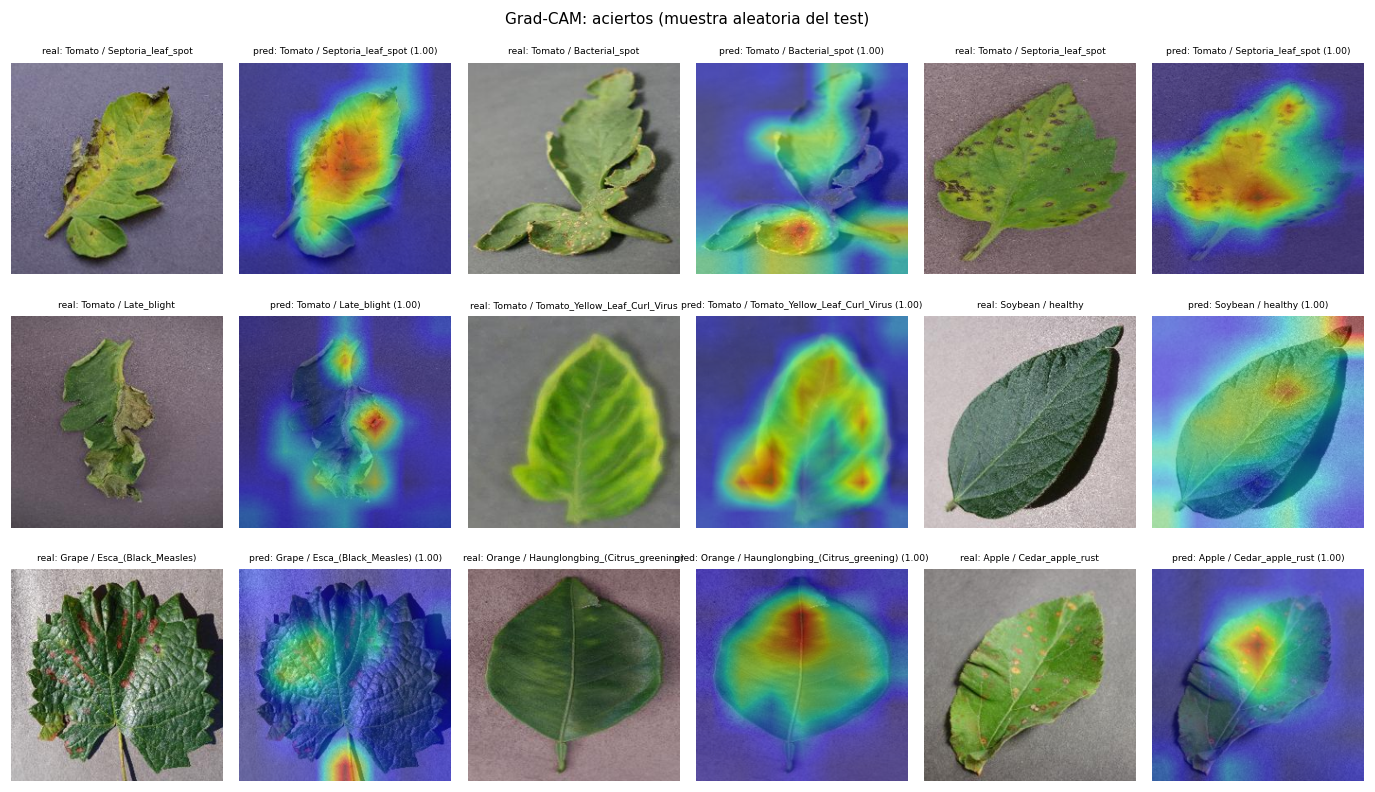

In [6]:
def show_cams(indices, arrs, y_true, y_pred, probs, ncols=3, title=None):
    n = len(indices)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols * 2, figsize=(ncols * 4.2, nrows * 2.5))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for k, i in enumerate(indices):
        r, c = divmod(k, ncols)
        cam, _, _ = gradcam(arrs[i], class_idx=int(y_pred[i]))
        ov, _ = overlay(arrs[i], cam)
        axes[r, 2 * c].imshow(arrs[i])
        axes[r, 2 * c + 1].imshow(ov)
        axes[r, 2 * c].set_title(f"real: {short(id2name[int(y_true[i])])}", fontsize=6)
        axes[r, 2 * c + 1].set_title(
            f"pred: {short(id2name[int(y_pred[i])])} ({probs[i].max():.2f})", fontsize=6
        )
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()

ok = np.where(y_pred == y_true)[0]
bad = np.where(y_pred != y_true)[0]
print("aciertos:", len(ok), "| errores:", len(bad))

show_cams(rng.choice(ok, size=9, replace=False), arrs, y_true, y_pred, probs,
          title="Grad-CAM: aciertos (muestra aleatoria del test)")

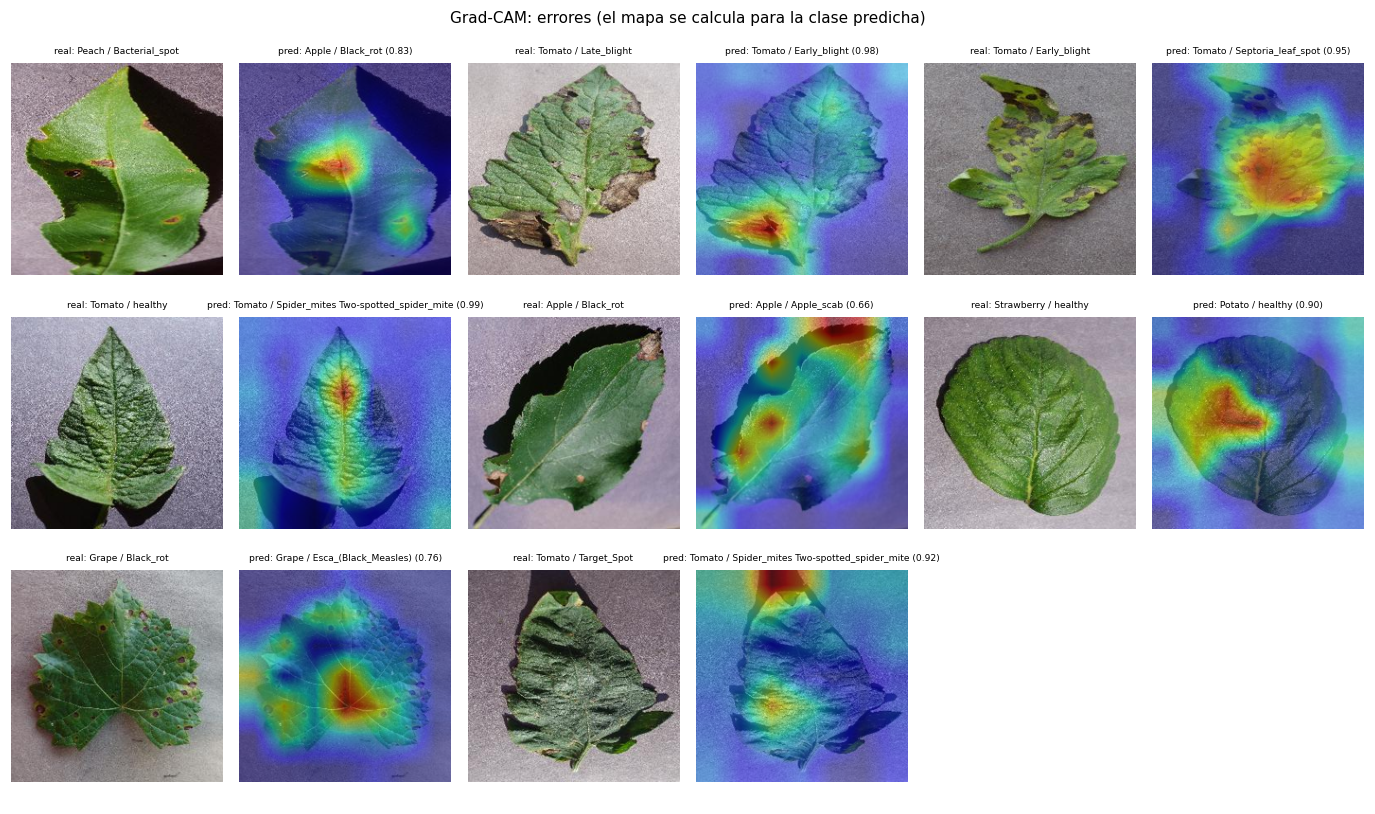

In [7]:
if len(bad) > 0:
    show_cams(rng.choice(bad, size=min(9, len(bad)), replace=False), arrs, y_true, y_pred, probs,
              title="Grad-CAM: errores (el mapa se calcula para la clase predicha)")

### 3.1 ¿Cuánto mira el modelo la hoja y cuánto el fondo? (heurística)

No hay máscaras de hoja, así que se aproximan: el fondo de PlantVillage es gris y poco saturado, mientras que la hoja tiene color. Se marcan como "hoja" los píxeles con saturación mayor a un umbral (`SAT_THRESHOLD = 0,25`) y se mide qué parte de la activación de Grad-CAM cae ahí, comparada con el área que ocupa esa "hoja". Antes de calcularlo, se muestran las máscaras de seis imágenes para comprobar que tengan sentido.

- **Ratio > 1:** el modelo se concentra en la hoja más de lo que se esperaría por azar.
- **Ratio ≈ 1:** reparte la atención sin distinguir hoja y fondo.

Es una **aproximación gruesa**: depende del umbral de color y no distingue lesiones de tejido sano.

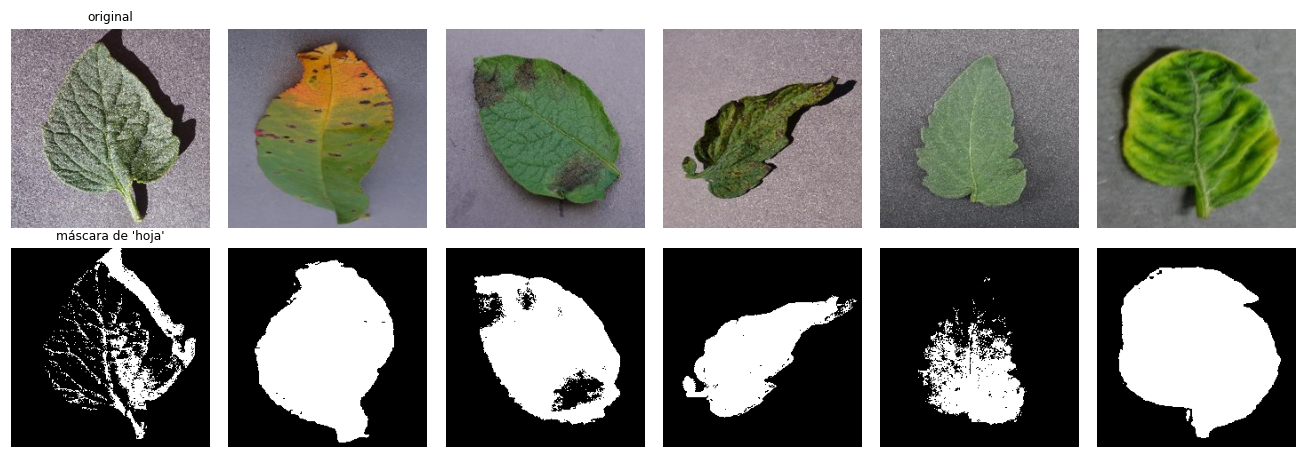

In [8]:
SAT_THRESHOLD = 0.25

def leaf_mask(arr_uint8, thr=SAT_THRESHOLD):
    hsv = np.asarray(Image.fromarray(arr_uint8).convert("HSV"), dtype=np.float32) / 255.0
    return hsv[..., 1] > thr

# Revisión visual de la máscara
show = rng.choice(np.where(y_true != bg_id)[0], size=6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
for k, i in enumerate(show):
    axes[0, k].imshow(arrs[i]); axes[0, k].axis("off")
    axes[1, k].imshow(leaf_mask(arrs[i]), cmap="gray"); axes[1, k].axis("off")
axes[0, 0].set_title("original", fontsize=8)
axes[1, 0].set_title("máscara de 'hoja'", fontsize=8)
plt.tight_layout()
plt.show()

Imágenes analizadas: 247
       area_hoja  cam_en_hoja    ratio
count    247.000      247.000  247.000
mean       0.421        0.586    1.430
std        0.138        0.183    0.378
min        0.112        0.044    0.199
25%        0.317        0.473    1.197
50%        0.419        0.617    1.403
75%        0.500        0.732    1.632
max        0.883        0.959    3.108

         count   mean  median
acierto                      
False        4  1.533   1.474
True       243  1.428   1.403


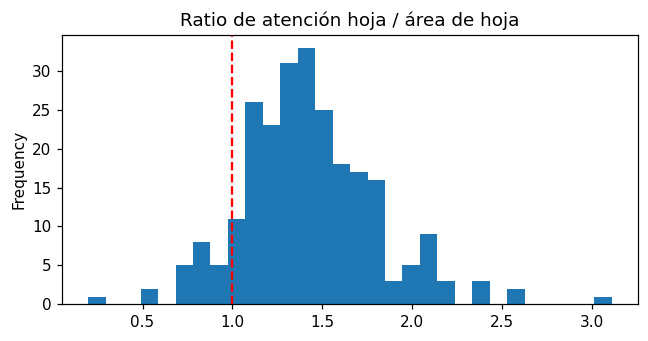

In [9]:
rows = []
for i in rng.choice(np.where(y_true != bg_id)[0], size=min(250, N), replace=False):
    cam, _, _ = gradcam(arrs[i], class_idx=int(y_pred[i]))
    _, cam_up = overlay(arrs[i], cam)
    m = leaf_mask(arrs[i])
    area = m.mean()
    if not (0.1 < area < 0.95) or cam_up.sum() == 0:
        continue
    inside = cam_up[m].sum() / cam_up.sum()
    rows.append({"area_hoja": area, "cam_en_hoja": inside, "ratio": inside / area,
                 "acierto": bool(y_pred[i] == y_true[i])})

df_focus = pd.DataFrame(rows)
print(f"Imágenes analizadas: {len(df_focus)}")
print(df_focus[["area_hoja", "cam_en_hoja", "ratio"]].describe().round(3))
print()
print(df_focus.groupby("acierto")["ratio"].agg(["count", "mean", "median"]).round(3))

df_focus["ratio"].plot.hist(bins=30, figsize=(6, 3.2), title="Ratio de atención hoja / área de hoja")
plt.axvline(1, color="red", linestyle="--")
plt.tight_layout()
plt.show()

## 4. Prueba de robustez con imágenes de otras fuentes

**Fuente por defecto: PlantDoc** (hojas recortadas de buscadores de imágenes, licencia CC BY 4.0). Comparte varios cultivos y enfermedades con PlantVillage, pero con fondos, iluminación y calidad muy distintos. Se leen de la carpeta local `data/plantdoc` si existe, o se descargan desde Hugging Face (`Project-AgML/plant_doc_classification`).

Para comparar, cada clase de PlantDoc se asocia manualmente con su equivalente en PlantVillage (`CLASS_MAP`). Las 28 clases de PlantDoc quedaron mapeadas; es un criterio manual que puede tener errores (por ejemplo, la "leaf spot" del pimiento se asignó a la mancha bacteriana). El código también admite fotos propias (`SOURCE = "folder"`), ordenadas en `data/external/<NombreDeClaseDePlantVillage>/`; esa opción no se usa en los resultados reportados.

In [10]:
SOURCE = "plantdoc"   # "plantdoc" | "folder"
EXT_FOLDER = os.path.join(ROOT, "data", "external")

# Equivalencia entre clases de PlantDoc (nombres en minúsculas) y de PlantVillage
CLASS_MAP = {
    "apple scab leaf": "Apple___Apple_scab",
    "apple rust leaf": "Apple___Cedar_apple_rust",
    "apple leaf": "Apple___healthy",
    "bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "bell_pepper leaf": "Pepper,_bell___healthy",
    "blueberry leaf": "Blueberry___healthy",
    "cherry leaf": "Cherry___healthy",
    "corn gray leaf spot": "Corn___Cercospora_leaf_spot Gray_leaf_spot",
    "corn leaf blight": "Corn___Northern_Leaf_Blight",
    "corn rust leaf": "Corn___Common_rust",
    "peach leaf": "Peach___healthy",
    "potato leaf early blight": "Potato___Early_blight",
    "potato leaf late blight": "Potato___Late_blight",
    "raspberry leaf": "Raspberry___healthy",
    "soyabean leaf": "Soybean___healthy",
    "squash powdery mildew leaf": "Squash___Powdery_mildew",
    "strawberry leaf": "Strawberry___healthy",
    "tomato early blight leaf": "Tomato___Early_blight",
    "tomato septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "tomato leaf": "Tomato___healthy",
    "tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "tomato leaf late blight": "Tomato___Late_blight",
    "tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "tomato mold leaf": "Tomato___Leaf_Mold",
    "tomato two spotted spider mites leaf": "Tomato___Spider_mites Two-spotted_spider_mite",
    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
}

In [11]:
ext_pil, ext_y, ext_src = [], [], []

if SOURCE == "plantdoc":
    from datasets import load_dataset, concatenate_datasets
    pdoc_local = os.path.join(ROOT, "data", "plantdoc")
    pdoc = load_dataset(pdoc_local if os.path.isdir(pdoc_local) else "Project-AgML/plant_doc_classification")
    pdoc_all = concatenate_datasets([pdoc[s] for s in pdoc.keys()])
    pdoc_names = pdoc_all.features["label"].names
    print("Clases de PlantDoc:", len(pdoc_names), "| imágenes:", len(pdoc_all))

    mapped = {i: name2id.get(CLASS_MAP.get(n.strip().lower())) for i, n in enumerate(pdoc_names)}
    print("\nClases de PlantDoc sin equivalente en PlantVillage (se excluyen):")
    for i, n in enumerate(pdoc_names):
        if mapped[i] is None:
            print("  -", n)

    for ex in pdoc_all:
        t = mapped[ex["label"]]
        if t is not None:
            ext_pil.append(ex["image"])
            ext_y.append(t)
            ext_src.append(pdoc_names[ex["label"]])

elif SOURCE == "folder":
    for cname in sorted(os.listdir(EXT_FOLDER)):
        if cname not in name2id:
            print("Carpeta ignorada (no coincide con una clase de PlantVillage):", cname)
            continue
        for fn in os.listdir(os.path.join(EXT_FOLDER, cname)):
            if fn.lower().endswith((".jpg", ".jpeg", ".png")):
                ext_pil.append(Image.open(os.path.join(EXT_FOLDER, cname, fn)))
                ext_y.append(name2id[cname])
                ext_src.append(cname)

ext_y = np.array(ext_y)
ext_arrs = np.stack([to_input(im) for im in ext_pil])
print("\nImágenes externas usadas:", len(ext_arrs), "| clases presentes:", len(set(ext_y.tolist())))

Clases de PlantDoc: 28 | imágenes: 2569

Clases de PlantDoc sin equivalente en PlantVillage (se excluyen):

Imágenes externas usadas: 2569 | clases presentes: 28


### 4.1 Métricas fuera de distribución

Se predicen las imágenes de PlantDoc con el modelo sin modificar y se reportan:

- **Accuracy top-1:** la clase con mayor probabilidad es la correcta.
- **Accuracy top-3:** la clase correcta está entre las tres con mayor probabilidad.
- **F1 macro:** promedio del F1 de las clases presentes en PlantDoc.

Debajo se muestran la accuracy por clase, las confusiones más frecuentes y qué clases predice más el modelo.

In [12]:
ext_probs = full_model.predict(ext_arrs.astype(np.float32), batch_size=64, verbose=0)
ext_pred = ext_probs.argmax(1)

top1 = float((ext_pred == ext_y).mean())
top3 = float(np.mean([ext_y[i] in np.argsort(ext_probs[i])[-3:] for i in range(len(ext_y))]))
labels_present = sorted(set(ext_y.tolist()))
f1_ext = f1_score(ext_y, ext_pred, labels=labels_present, average="macro", zero_division=0)

print(f"Accuracy top-1:            {top1:.3f}")
print(f"Accuracy top-3:            {top3:.3f}")
print(f"F1 macro (clases presentes): {f1_ext:.3f}")
print(f"Referencia en PlantVillage (test, notebook 03): accuracy 0.987 | F1 macro 0.982")

Accuracy top-1:            0.088
Accuracy top-3:            0.229
F1 macro (clases presentes): 0.095
Referencia en PlantVillage (test, notebook 03): accuracy 0.987 | F1 macro 0.982


In [13]:
per_class = (
    pd.DataFrame({"clase": [id2name[i] for i in ext_y], "ok": ext_pred == ext_y})
    .groupby("clase")["ok"].agg(["mean", "count"])
    .rename(columns={"mean": "accuracy", "count": "n"})
    .sort_values("accuracy")
)
per_class.round(3)

,accuracy,n
clase,,
Apple___Cedar_apple_rust,0.000,88
Grape___Black_rot,0.000,64
Tomato___Tomato_mosaic_virus,0.000,54
Tomato___Leaf_Mold,0.000,91
Tomato___Spider_mites Two-spotted_spider_mite,0.000,2
Tomato___Tomato_Yellow_Leaf_Curl_Virus,0.000,75
Tomato___Bacterial_spot,0.009,110
Soybean___healthy,0.015,65
Tomato___healthy,0.016,63


In [14]:
conf = pd.Series(
    [(id2name[a], id2name[b]) for a, b in zip(ext_y, ext_pred) if a != b]
).value_counts().head(10)
pd.DataFrame({"cantidad": conf.values, "real → predicha": [f"{a}  →  {b}" for a, b in conf.index]})

,cantidad,real → predicha
0,99,Raspberry___healthy → Background_without_leaves
1,90,Blueberry___healthy → Background_without_leaves
2,88,Peach___healthy → Background_without_leaves
3,83,Strawberry___healthy → Background_without_le...
4,71,Tomato___Septoria_leaf_spot → Background_wit...
5,65,Apple___healthy → Background_without_leaves
6,62,Corn___Northern_Leaf_Blight → Background_wit...
7,56,Tomato___Bacterial_spot → Background_without...
8,54,Tomato___Tomato_Yellow_Leaf_Curl_Virus → Bac...
9,52,Tomato___healthy → Background_without_leaves


In [15]:
dist = pd.Series([id2name[i] for i in ext_pred]).value_counts().head(8)
print("Clases más predichas sobre las imágenes externas:")
print(dist)
print("\nPredichas como fondo (sin hoja):", int((ext_pred == bg_id).sum()))

Clases más predichas sobre las imágenes externas:
Background_without_leaves                     1397
Strawberry___Leaf_scorch                       202
Tomato___Late_blight                           191
Corn___Cercospora_leaf_spot Gray_leaf_spot     105
Corn___healthy                                  78
Corn___Northern_Leaf_Blight                     75
Tomato___Early_blight                           68
Pepper,_bell___Bacterial_spot                   49
Name: count, dtype: int64

Predichas como fondo (sin hoja): 1397


### 4.1.1 Diagnósticos: ¿se explica el fallo por la clase fondo o por el preprocesado?

Como más de la mitad de las imágenes se predice como `Background_without_leaves`, se prueban dos explicaciones posibles sin reentrenar el modelo:

1. **Ignorar la clase fondo al predecir:** se anula su probabilidad y se elige entre las 38 clases restantes.
2. **Recorte cuadrado centrado** en lugar de estirar cada imagen a 224x224, porque las imágenes de PlantDoc no son cuadradas.

In [16]:
# Diagnóstico 1: ignorar la clase fondo al predecir
p = ext_probs.copy()
p[:, bg_id] = 0
p /= p.sum(1, keepdims=True)
pred_nb = p.argmax(1)

top1_nb = float((pred_nb == ext_y).mean())
top3_nb = float(np.mean([ext_y[i] in np.argsort(p[i])[-3:] for i in range(len(ext_y))]))
f1_nb = f1_score(ext_y, pred_nb, labels=labels_present, average="macro", zero_division=0)
print(f"Sin la clase fondo -> top-1 {top1_nb:.3f} | top-3 {top3_nb:.3f} | F1 macro {f1_nb:.3f}")

Sin la clase fondo -> top-1 0.123 | top-3 0.278 | F1 macro 0.117


In [17]:
# Diagnóstico 2: recorte cuadrado centrado en lugar de estirar la imagen
def to_input_crop(pil_img):
    im = pil_img.convert("RGB")
    s = min(im.size)
    left, top = (im.size[0] - s) // 2, (im.size[1] - s) // 2
    return np.asarray(im.crop((left, top, left + s, top + s)).resize(IMG_SIZE), dtype=np.uint8)

arrs_crop = np.stack([to_input_crop(im) for im in ext_pil])
probs_crop = full_model.predict(arrs_crop.astype(np.float32), batch_size=64, verbose=0)
pred_crop = probs_crop.argmax(1)
print(f"Recorte cuadrado -> top-1 {(pred_crop == ext_y).mean():.3f} | "
      f"predichas como fondo: {int((pred_crop == bg_id).sum())}")

Recorte cuadrado -> top-1 0.104 | predichas como fondo: 1293


### 4.2 ¿La confianza del modelo sirve para detectar errores?

La confianza es la probabilidad máxima que asigna el modelo. Si el modelo fuera confiable fuera de distribución, sus errores tendrían baja confianza y se podrían rechazar. Se mide cuánta accuracy se obtiene si solo se aceptan las predicciones que superan un umbral de confianza y qué fracción de las imágenes (cobertura) se acepta.

In [18]:
conf_max = ext_probs.max(1)
correct = ext_pred == ext_y
print(f"Confianza media — aciertos: {conf_max[correct].mean():.3f} | errores: {conf_max[~correct].mean():.3f}")

rows = []
for thr in [0.0, 0.5, 0.7, 0.9, 0.95, 0.99]:
    m = conf_max >= thr
    rows.append({"umbral": thr, "cobertura": m.mean(),
                 "accuracy_aceptadas": correct[m].mean() if m.any() else np.nan})
pd.DataFrame(rows).round(3)

Confianza media — aciertos: 0.894 | errores: 0.908


,umbral,cobertura,accuracy_aceptadas
0,0.00,1.000,0.088
1,0.50,0.976,0.087
2,0.70,0.866,0.086
3,0.90,0.725,0.084
4,0.95,0.659,0.082
5,0.99,0.529,0.075


### 4.3 Grad-CAM sobre imágenes externas

Mapas de calor de seis aciertos y seis errores al azar de PlantDoc, calculados para la clase predicha. Permiten ver si el modelo se fija en las lesiones cuando acierta y qué hace cuando se equivoca.

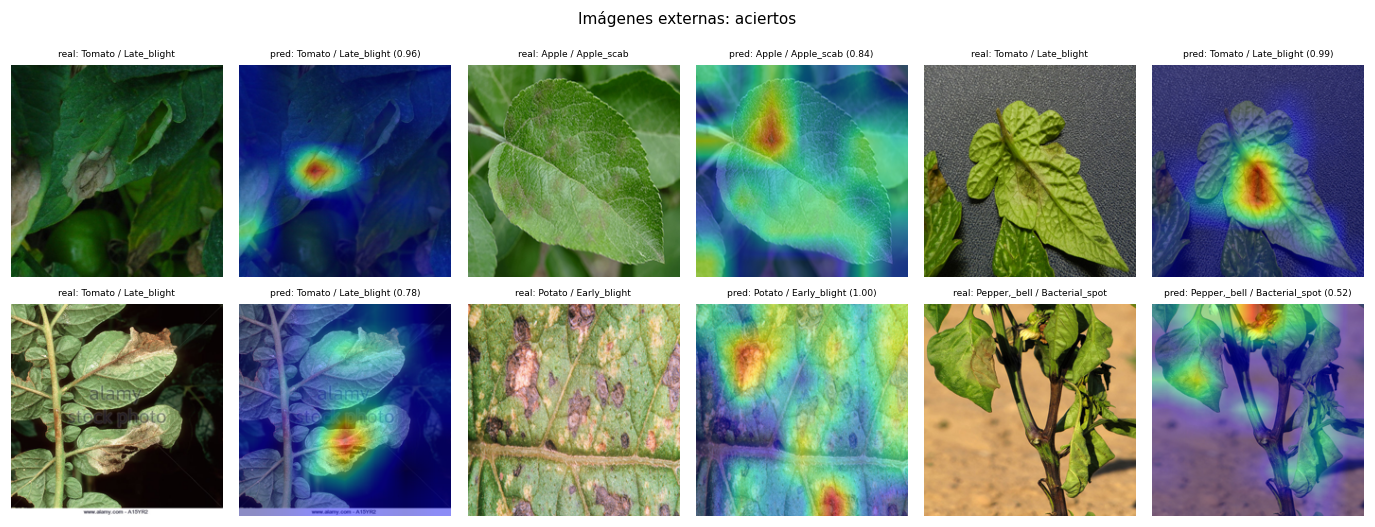

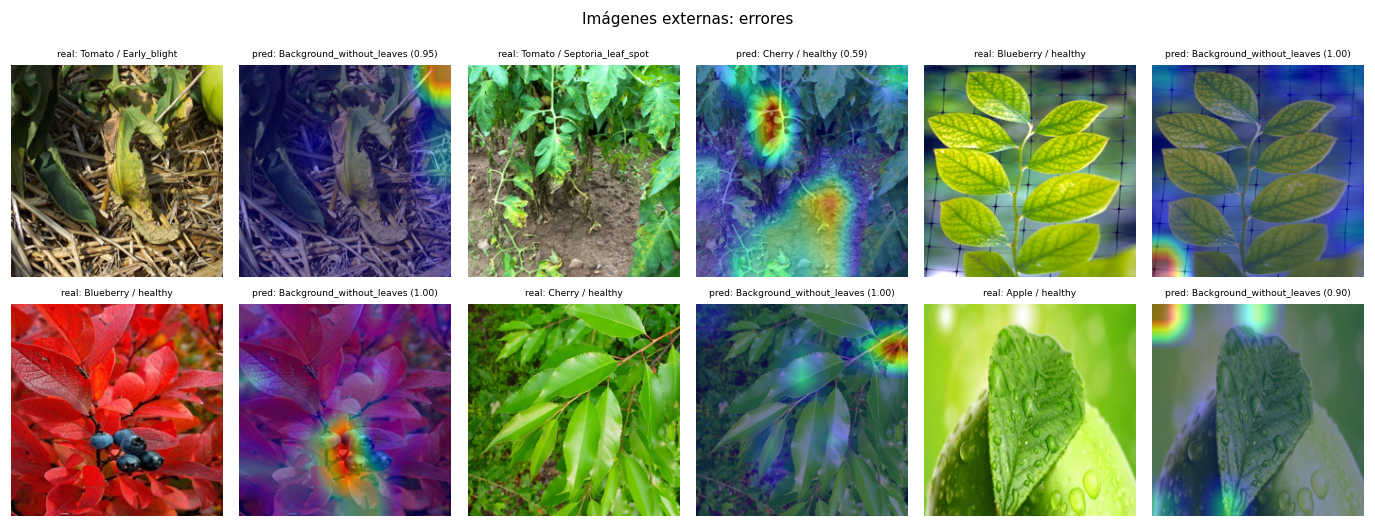

In [19]:
ext_ok = np.where(ext_pred == ext_y)[0]
ext_bad = np.where(ext_pred != ext_y)[0]
if len(ext_ok) >= 6:
    show_cams(rng.choice(ext_ok, size=6, replace=False), ext_arrs, ext_y, ext_pred, ext_probs,
              title="Imágenes externas: aciertos")
if len(ext_bad) >= 6:
    show_cams(rng.choice(ext_bad, size=6, replace=False), ext_arrs, ext_y, ext_pred, ext_probs,
              title="Imágenes externas: errores")

## 5. Guardar resultados

Se guardan las métricas de robustez y el ratio de atención en `reports/robustez_plantdoc.json`. Este reporte no corresponde a un experimento de entrenamiento, por lo que no aparece en las tablas comparativas de los notebooks 02 y 03.

In [20]:
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)
results = {
    "modelo": MODEL_NAME,
    "fuente_externa": SOURCE,
    "n_imagenes_externas": int(len(ext_y)),
    "n_clases_externas": int(len(labels_present)),
    "accuracy_top1": round(top1, 4),
    "accuracy_top3": round(top3, 4),
    "f1_macro": round(float(f1_ext), 4),
    "referencia_plantvillage_accuracy": 0.987,
    "referencia_plantvillage_f1_macro": 0.982,
    "ratio_atencion_hoja_mediana": round(float(df_focus["ratio"].median()), 3),
}
out = os.path.join(ROOT, "reports", f"robustez_{SOURCE}.json")
with open(out, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("Guardado en", out)
results

Guardado en c:\Users\Carlos\Desktop\Python-Prep\proyecto_vision_plantvillage\reports\robustez_plantdoc.json


{'modelo': 'tl_mobilenetv3small_224_cw0.5_full_full.keras',
 'fuente_externa': 'plantdoc',
 'n_imagenes_externas': 2569,
 'n_clases_externas': 28,
 'accuracy_top1': 0.0876,
 'accuracy_top3': 0.2289,
 'f1_macro': 0.0954,
 'referencia_plantvillage_accuracy': 0.987,
 'referencia_plantvillage_f1_macro': 0.982,
 'ratio_atencion_hoja_mediana': 1.403}

## 6. Conclusiones

- **Modelo analizado:** el de la configuración final del notebook 03 (accuracy 0,987 y F1 macro 0,982 en el test de PlantVillage; accuracy 0,980 en la muestra de 400 imágenes usada aquí).
- **Grad-CAM en PlantVillage:** calculado sobre el logit, el mapa cae sobre la hoja (a veces sobre lesiones, a veces sobre tejido sano cercano) y no sobre el fondo. Con una máscara aproximada de hoja por saturación, el ratio de atención mediano es 1,40 sobre 247 imágenes. Entre ellas solo hay 4 errores, por lo que no se pueden comparar aciertos y errores.
- **Robustez:** en PlantDoc (2.569 imágenes, 28 clases mapeadas) el modelo cae a accuracy top-1 de 0,088, top-3 de 0,229 y F1 macro de 0,095, contra 0,987 y 0,982 en PlantVillage.
- **Qué clases se rompen:** casi todas. La mejor es `Tomato___Late_blight` (0,459) y las clases sanas no superan 0,06. El 54 % de las imágenes (1.397) se predice como `Background_without_leaves`: el modelo trata las escenas de campo como "sin hoja". Algunas clases tienen muy pocas imágenes en PlantDoc (los ácaros del tomate solo tienen 2), por lo que su accuracy por clase no es informativa.
- **Diagnósticos (sección 4.1.1):** ignorar la clase fondo al predecir sube el top-1 solo a 0,123; usar un recorte cuadrado en lugar de estirar la imagen lo deja en 0,104. El fallo no se explica por esos dos factores.
- **Confianza:** la confianza media es 0,894 en aciertos y 0,908 en errores. Aceptando solo predicciones con confianza ≥ 0,99 (53 % de cobertura), la accuracy sigue en 0,075. La probabilidad softmax no sirve para rechazar entradas fuera de distribución.
- **Grad-CAM en PlantDoc:** en los aciertos, el mapa cae sobre las lesiones; en los errores aparecen una o dos manchas dispersas, sin relación con las lesiones.
- **Interpretación:** el colapso parece un cambio de dominio general (iluminación, escala, fondos, calidad) y no un problema de atención al fondo. Es una hipótesis: no se probó.
- **Limitaciones:** mapeo de clases entre datasets manual, ruido de etiquetas en PlantDoc, clases con muy pocas imágenes, máscara de hoja heurística, mapas de baja resolución (7x7), revisión visual de Grad-CAM sobre una muestra pequeña y split de PlantVillage sin agrupar por hoja.
- **Siguientes pasos:** augmentation fuerte, fine-tuning, incorporar parte de las imágenes de campo al entrenamiento y un método de detección de entradas fuera de distribución.